# 01 – Nintendo Sales: Data Overview

## Project Goal

This notebook explores Nintendo's worldwide hardware and software sales across selected console generations.

The goal is to examine the dataset, check its data quality, and calculate the software-to-hardware ratio.

## Data Source

Source: [Nintendo – Dedicated Video Game Sales Units](https://www.nintendo.co.jp/ir/en/finance/hard_soft/index.html)

Data as of: September 30, 2026.

In [13]:
import pandas as pd

In [14]:
df = pd.read_csv("../data/raw/nintendo_lifetime_sales.csv")

df

,platform,hardware_million,software_million
0,Switch 2,26.35,73.21
1,Switch,157.20,1593.87
2,Wii U,13.56,103.60
3,Wii,101.63,921.85


## Data Overview

First, I examined the structure, data types, and statistical characteristics of the dataset.

In [15]:
df.shape

(4, 3)

In [16]:
df.columns

Index(['platform', 'hardware_million', 'software_million'], dtype='str')

In [17]:
df.dtypes

platform                str
hardware_million    float64
software_million    float64
dtype: object

In [18]:
df.describe()

,hardware_million,software_million
count,4.000000,4.000000
mean,74.685000,673.132500
std,67.348091,728.901505
min,13.560000,73.210000
25%,23.152500,96.002500
50%,63.990000,512.725000
75%,115.522500,1089.855000
max,157.200000,1593.870000


## Data Quality

Before analyzing the sales data, I checked for missing values and duplicate rows to assess the dataset's quality.

In [19]:
df.isnull().sum()

platform            0
hardware_million    0
software_million    0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

## Software-to-Hardware Ratio

To compare software and hardware sales across Nintendo consoles, I calculated the software-to-hardware ratio.

The ratio represents the number of software units sold per hardware unit.

In [21]:
df["software_hardware_ratio"] = (
    df["software_million"] / df["hardware_million"]
)

df


,platform,hardware_million,software_million,software_hardware_ratio
0,Switch 2,26.35,73.21,2.778368
1,Switch,157.20,1593.87,10.139122
2,Wii U,13.56,103.60,7.640118
3,Wii,101.63,921.85,9.070648


In [22]:
df["software_hardware_ratio"] = df["software_hardware_ratio"].round(2)

df

,platform,hardware_million,software_million,software_hardware_ratio
0,Switch 2,26.35,73.21,2.78
1,Switch,157.20,1593.87,10.14
2,Wii U,13.56,103.60,7.64
3,Wii,101.63,921.85,9.07


## Visualization

The following bar chart compares the software-to-hardware ratio across the four Nintendo consoles.

In [23]:
import matplotlib.pyplot as plt

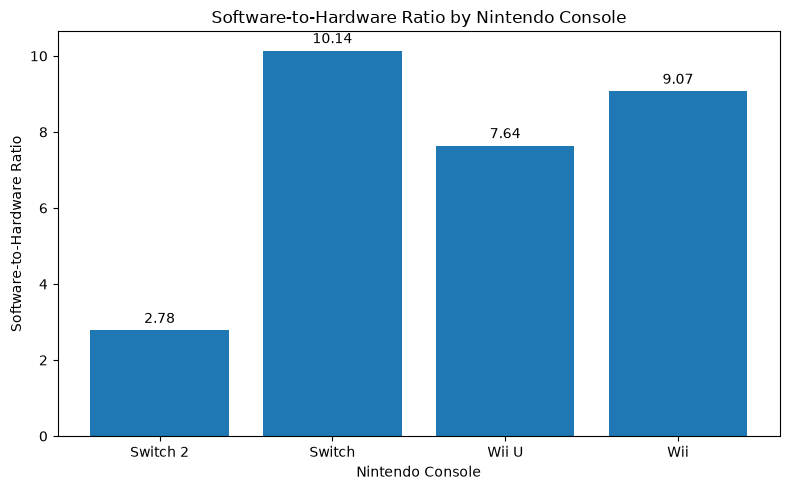

In [24]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    df["platform"],
    df["software_hardware_ratio"]
)

plt.title("Software-to-Hardware Ratio by Nintendo Console")
plt.xlabel("Nintendo Console")
plt.ylabel("Software-to-Hardware Ratio")

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../reports/figures/software_hardware_ratio.png", dpi=300)
plt.show()

## Interpretation

The Nintendo Switch has the highest software-to-hardware ratio (10.14), while the Switch 2 has the lowest (2.78).

However, these results must be interpreted carefully. The Switch 2 launched in June 2025, whereas the original Switch launched in March 2017.

Since the dataset contains cumulative lifetime sales, the consoles have had different amounts of time to accumulate sales. Therefore, their ratios are not directly comparable.